# Indicators For Upcoming Financial "Crash"

[SOURCE: U.S. Bureau of Labor Statistics - Current Employment Statistics](https://download.bls.gov/pub/time.series/ce/ce.series)

In [1]:
from blsutils import BLSClient
import matplotlib.pyplot as plt
import polars as pl
pl.Config.set_tbl_rows(24);

### Total # of People Employed from 2007 thru 2026 so that we can include 2008-2009 Recession Period, Pre-COVID, COVID, and recent data

Data through September 2026:

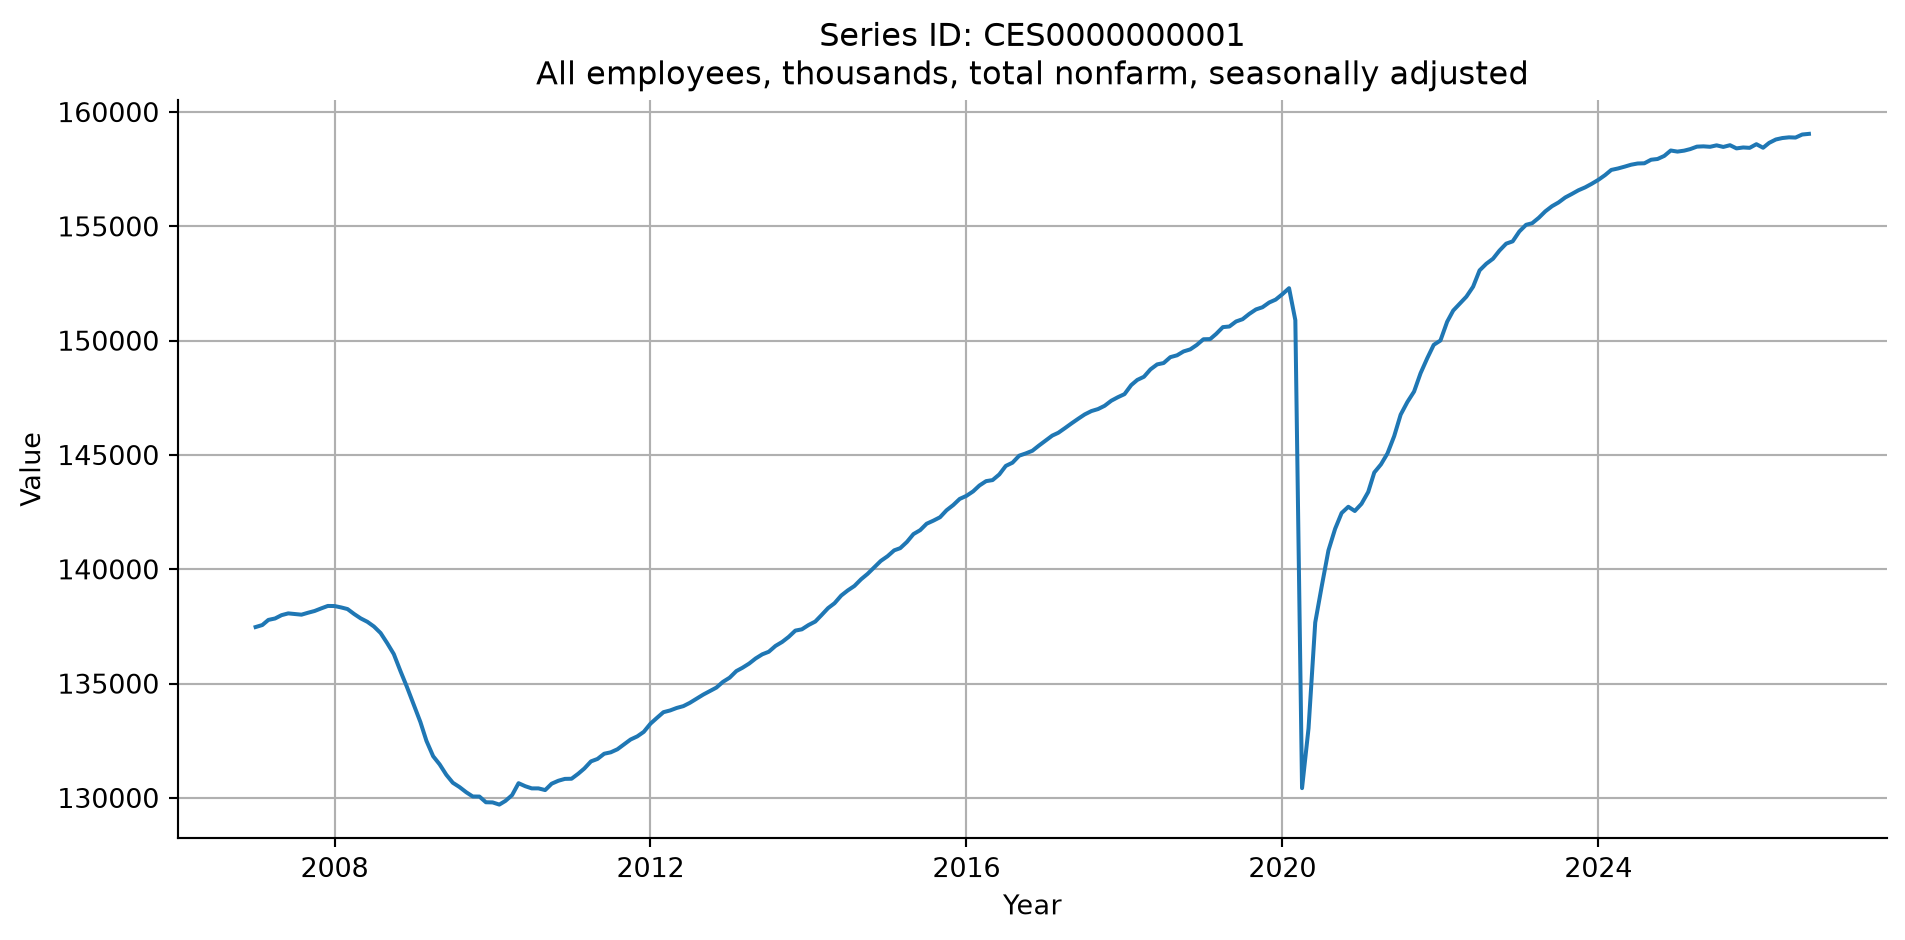

Last 13 recent months of data
shape: (13, 6)
┌───────────────┬────────────┬──────┬────────┬──────────┬────────────┐
│ series_id     ┆ year_month ┆ year ┆ period ┆ value    ┆ value_diff │
│ ---           ┆ ---        ┆ ---  ┆ ---    ┆ ---      ┆ ---        │
│ str           ┆ date       ┆ str  ┆ str    ┆ f64      ┆ f64        │
╞═══════════════╪════════════╪══════╪════════╪══════════╪════════════╡
│ CES0000000001 ┆ 2025-09-01 ┆ 2025 ┆ M09    ┆ 158548.0 ┆ 76.0       │
│ CES0000000001 ┆ 2025-10-01 ┆ 2025 ┆ M10    ┆ 158408.0 ┆ -140.0     │
│ CES0000000001 ┆ 2025-11-01 ┆ 2025 ┆ M11    ┆ 158449.0 ┆ 41.0       │
│ CES0000000001 ┆ 2025-12-01 ┆ 2025 ┆ M12    ┆ 158432.0 ┆ -17.0      │
│ CES0000000001 ┆ 2026-01-01 ┆ 2026 ┆ M01    ┆ 158592.0 ┆ 160.0      │
│ CES0000000001 ┆ 2026-02-01 ┆ 2026 ┆ M02    ┆ 158436.0 ┆ -156.0     │
│ CES0000000001 ┆ 2026-03-01 ┆ 2026 ┆ M03    ┆ 158650.0 ┆ 214.0      │
│ CES0000000001 ┆ 2026-04-01 ┆ 2026 ┆ M04    ┆ 158798.0 ┆ 148.0      │
│ CES0000000001 ┆ 2026-05-01 ┆ 2

In [2]:
with BLSClient() as client:
    df = client.fetch_df(series_id="CES0000000001", start_year=2007, end_year=2026)
    df = (
        df
        .sort(
            pl.col("year_month")
        )
        .with_columns(
            value_diff=pl.col("value").diff()
        )
    )
    client.plot_bls_series(df, "All employees, thousands, total nonfarm, seasonally adjusted")
    print("Last 13 recent months of data")
    print(df.tail(13))

**There was a little bit of up-tick for beginning of 2026, but the slope or trend is still very low compared to pre-COVID.**

### Let's look at private sector employment

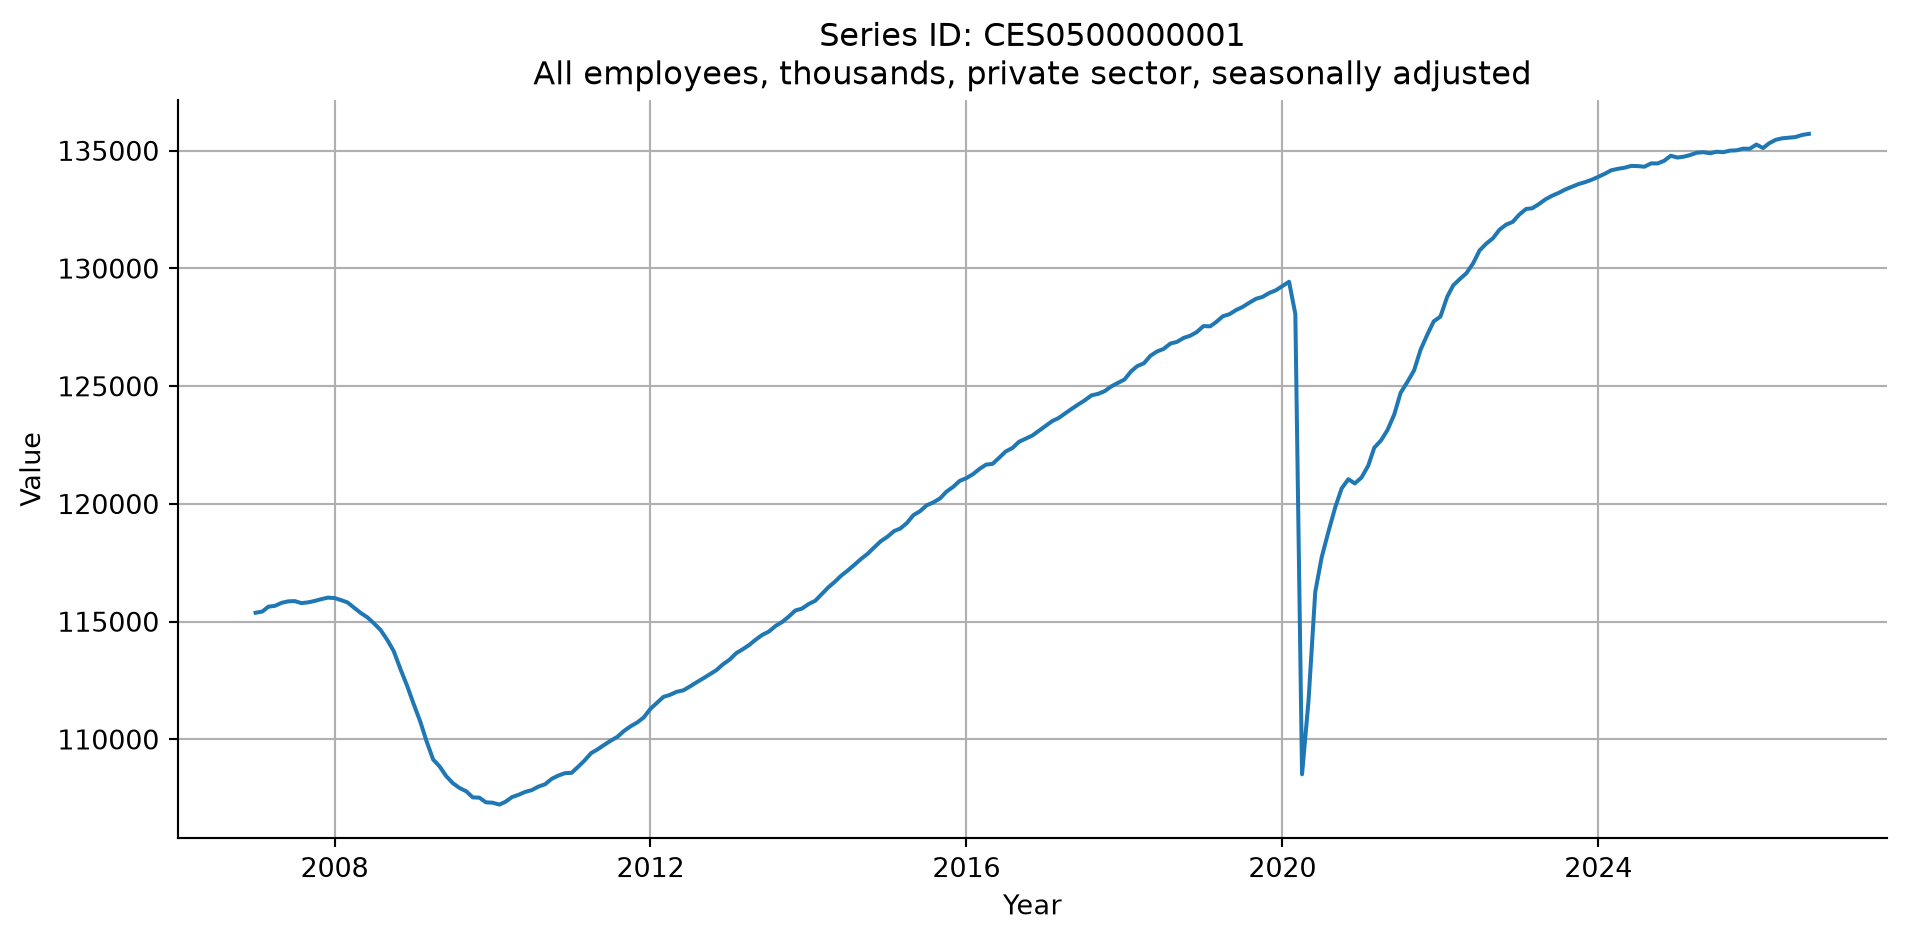

Last 13 recent months of data
shape: (13, 6)
┌───────────────┬────────────┬──────┬────────┬──────────┬────────────┐
│ series_id     ┆ year_month ┆ year ┆ period ┆ value    ┆ value_diff │
│ ---           ┆ ---        ┆ ---  ┆ ---    ┆ ---      ┆ ---        │
│ str           ┆ date       ┆ str  ┆ str    ┆ f64      ┆ f64        │
╞═══════════════╪════════════╪══════╪════════╪══════════╪════════════╡
│ CES0500000001 ┆ 2025-09-01 ┆ 2025 ┆ M09    ┆ 135005.0 ┆ 68.0       │
│ CES0500000001 ┆ 2025-10-01 ┆ 2025 ┆ M10    ┆ 135018.0 ┆ 13.0       │
│ CES0500000001 ┆ 2025-11-01 ┆ 2025 ┆ M11    ┆ 135090.0 ┆ 72.0       │
│ CES0500000001 ┆ 2025-12-01 ┆ 2025 ┆ M12    ┆ 135083.0 ┆ -7.0       │
│ CES0500000001 ┆ 2026-01-01 ┆ 2026 ┆ M01    ┆ 135263.0 ┆ 180.0      │
│ CES0500000001 ┆ 2026-02-01 ┆ 2026 ┆ M02    ┆ 135115.0 ┆ -148.0     │
│ CES0500000001 ┆ 2026-03-01 ┆ 2026 ┆ M03    ┆ 135317.0 ┆ 202.0      │
│ CES0500000001 ┆ 2026-04-01 ┆ 2026 ┆ M04    ┆ 135467.0 ┆ 150.0      │
│ CES0500000001 ┆ 2026-05-01 ┆ 2

In [3]:
with BLSClient() as client:
    df = client.fetch_df(series_id="CES0500000001", start_year=2007, end_year=2026)
    df = (
        df
        .sort(
            pl.col("year_month")
        )
        .with_columns(
            value_diff=pl.col("value").diff()
        )
    )
    client.plot_bls_series(df, "All employees, thousands, private sector, seasonally adjusted")
    print("Last 13 recent months of data")
    print(df.tail(13))

**We recovered after the huge job losses in February 2026.  But recent months trend does not look favorable.**

## Now, let's look at difference or change in total employment numbers

### 3-Month Average Change (in thousands), total nonfarm, seasonally adjusted

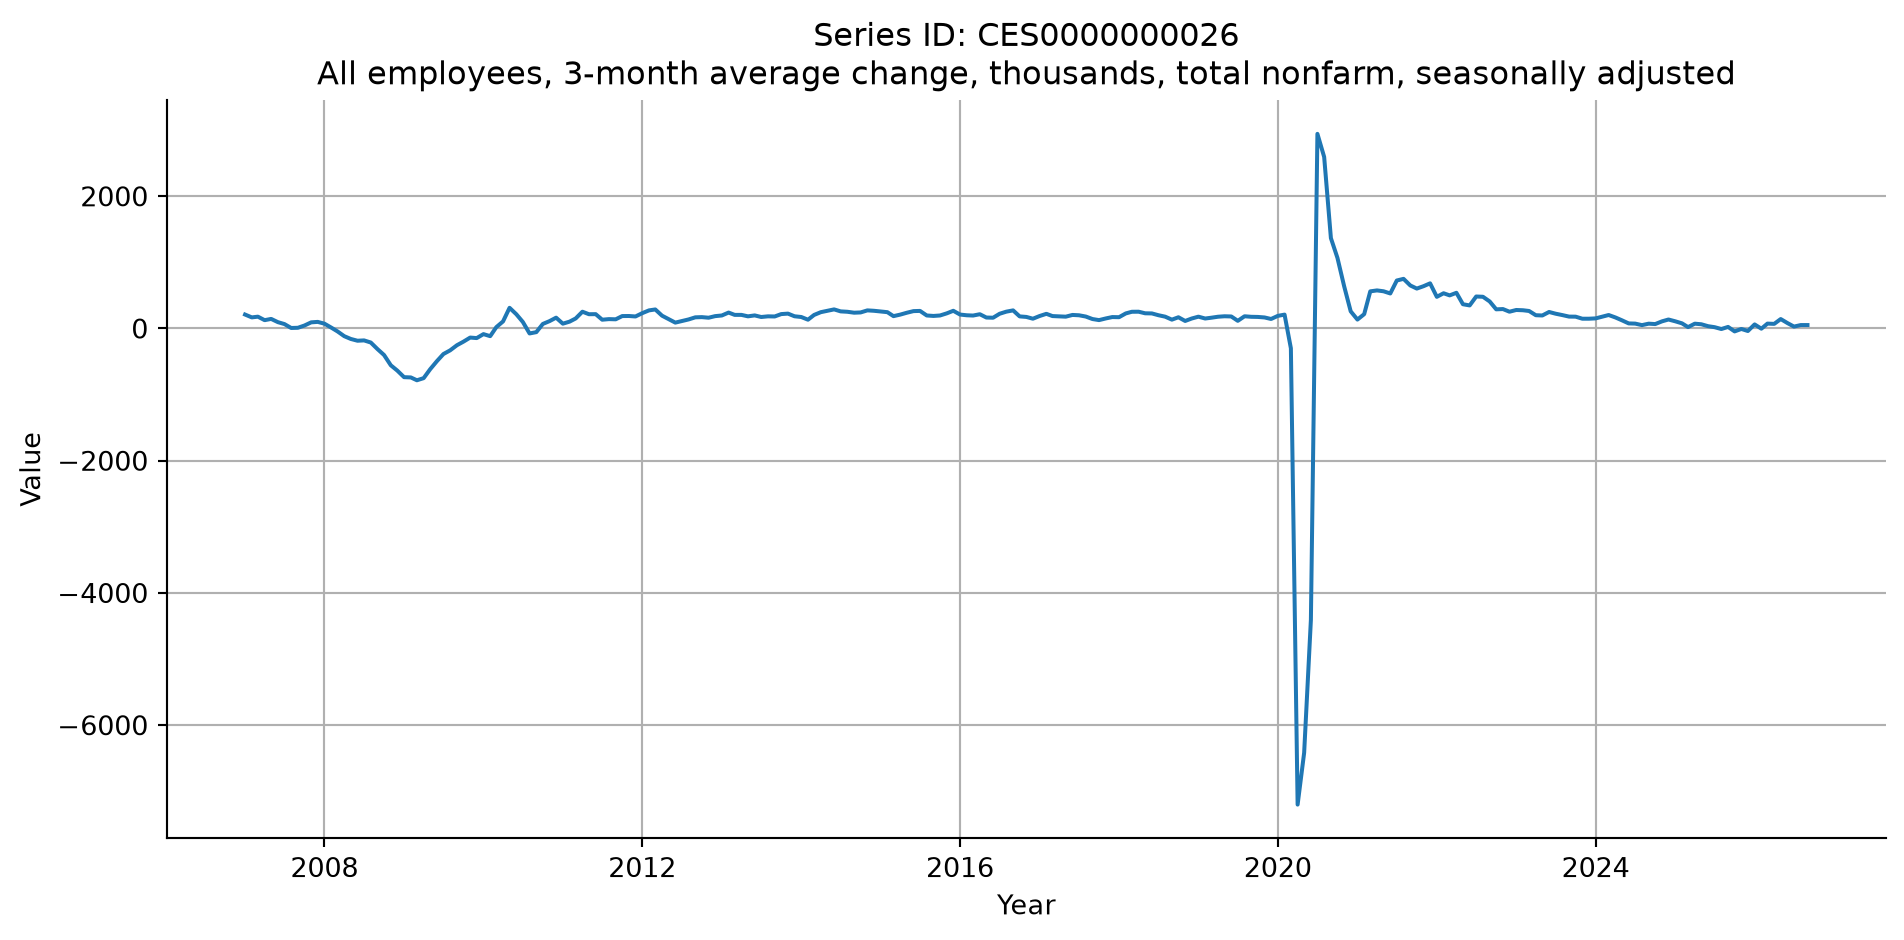

Last 5 recent months of data
shape: (5, 5)
┌───────────────┬────────────┬──────┬────────┬───────┐
│ series_id     ┆ year_month ┆ year ┆ period ┆ value │
│ ---           ┆ ---        ┆ ---  ┆ ---    ┆ ---   │
│ str           ┆ date       ┆ str  ┆ str    ┆ f64   │
╞═══════════════╪════════════╪══════╪════════╪═══════╡
│ CES0000000026 ┆ 2026-05-01 ┆ 2026 ┆ M05    ┆ 142.0 │
│ CES0000000026 ┆ 2026-06-01 ┆ 2026 ┆ M06    ┆ 81.0  │
│ CES0000000026 ┆ 2026-07-01 ┆ 2026 ┆ M07    ┆ 28.0  │
│ CES0000000026 ┆ 2026-08-01 ┆ 2026 ┆ M08    ┆ 51.0  │
│ CES0000000026 ┆ 2026-09-01 ┆ 2026 ┆ M09    ┆ 51.0  │
└───────────────┴────────────┴──────┴────────┴───────┘


In [4]:
with BLSClient() as client:
    df = client.fetch_df(series_id="CES0000000026", start_year=2007, end_year=2026)
    client.plot_bls_series(df, "All employees, 3-month average change, thousands, total nonfarm, seasonally adjusted")
    print("Last 5 recent months of data")
    print(df.tail(5))

**We see that the values pre-COVID are further away from zero axis, where as in 2024 thru 2026, values are closer to zero axis**

But, let's quantify pre-COVID employment vs employment during 2024-2026.

Average of jobs added from 2017 thru 2019:

In [5]:
#| echo: true
(
    df
    .filter(
        pl.col("year").is_in(["2017","2018","2019"])
    )
    .select(
        pl.col("value").mean().alias("avg_value")
    )
)

avg_value
f64
178.361111


Average of jobs added from 2024 thru 2026:

In [6]:
#| echo: true
(
    df
    .filter(
        pl.col("year").is_in(["2024","2025","2026"])
    )
    .select(
        pl.col("value").mean().alias("avg_value")
    )
)

avg_value
f64
68.727273


On average, during the few years before COVID, 178 thousand jobs were added.  From 2024 thru 2026, only 69 thousand jobs were added on average.

### 3-Month Average Change (in thousands), private sector, seasonally adjusted

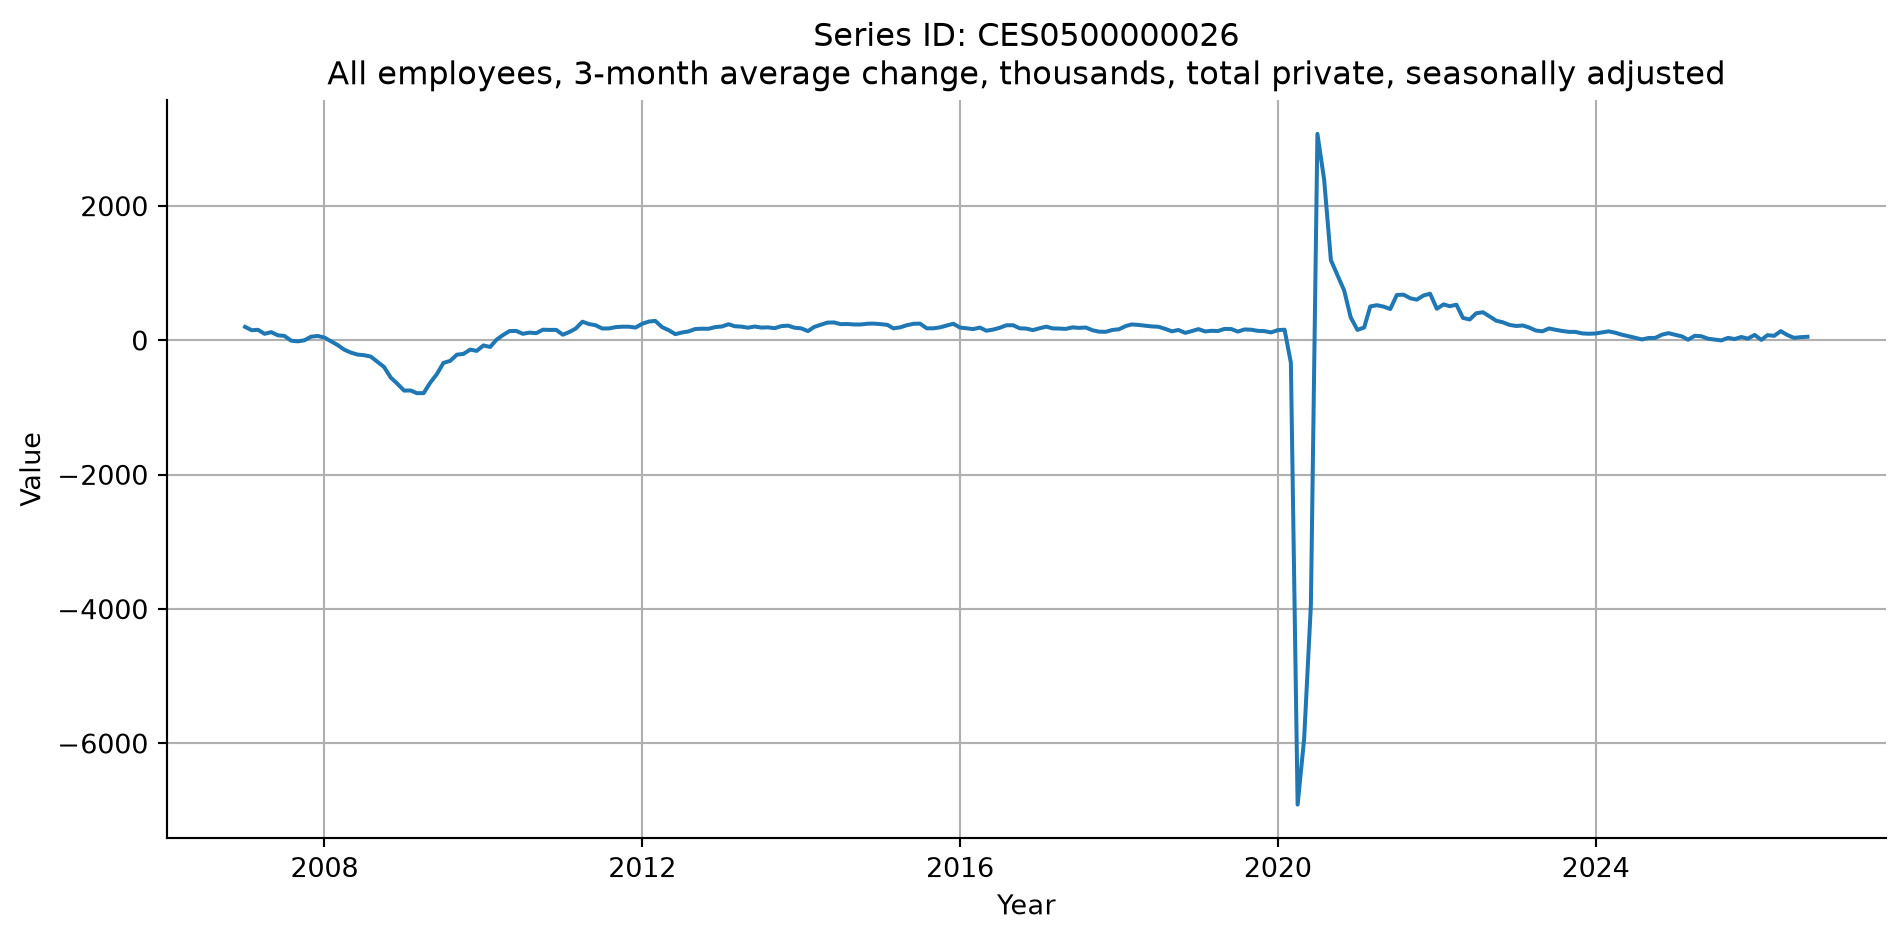

Last 5 recent months of data
shape: (5, 5)
┌───────────────┬────────────┬──────┬────────┬───────┐
│ series_id     ┆ year_month ┆ year ┆ period ┆ value │
│ ---           ┆ ---        ┆ ---  ┆ ---    ┆ ---   │
│ str           ┆ date       ┆ str  ┆ str    ┆ f64   │
╞═══════════════╪════════════╪══════╪════════╪═══════╡
│ CES0500000026 ┆ 2026-05-01 ┆ 2026 ┆ M05    ┆ 138.0 │
│ CES0500000026 ┆ 2026-06-01 ┆ 2026 ┆ M06    ┆ 79.0  │
│ CES0500000026 ┆ 2026-07-01 ┆ 2026 ┆ M07    ┆ 38.0  │
│ CES0500000026 ┆ 2026-08-01 ┆ 2026 ┆ M08    ┆ 48.0  │
│ CES0500000026 ┆ 2026-09-01 ┆ 2026 ┆ M09    ┆ 54.0  │
└───────────────┴────────────┴──────┴────────┴───────┘


In [7]:
with BLSClient() as client:
    df = client.fetch_df(series_id="CES0500000026", start_year=2007, end_year=2026)
    client.plot_bls_series(df, "All employees, 3-month average change, thousands, total private, seasonally adjusted")
    print("Last 5 recent months of data")
    print(df.tail(5))

**For private sector, same trend as before: pre-COVID, values were further away from zero, but in 2024 thru 2026, values are closer to zero.  Again let's quantify pre-COVID vs 2024 thru 2026:**

Average of jobs added from 2017 thru 2019:

In [8]:
#| echo: true
(
    df
    .filter(
        pl.col("year").is_in(["2017","2018","2019"])
    )
    .select(
        pl.col("value").mean().alias("avg_value")
    )
)

avg_value
f64
167.055556


Average of jobs added from 2024 thru 2026:

In [9]:
#| echo: true
(
    df
    .filter(
        pl.col("year").is_in(["2024","2025","2026"])
    )
    .select(
        pl.col("value").mean().alias("avg_value")
    )
)

avg_value
f64
60.181818


On average, during the few years before COVID, 167 thousand jobs were added.  From 2024 thru 2026, only 60 thousand jobs were added on average.

## Let's take population into account of employment-eligible persons (16 years old and over) using series ID "LNS12300000"

[SOURCE: U.S. Bureau of Labor Statistics - National Unemployment](https://download.bls.gov/pub/time.series/ln/ln.series)

Data through September 2026:

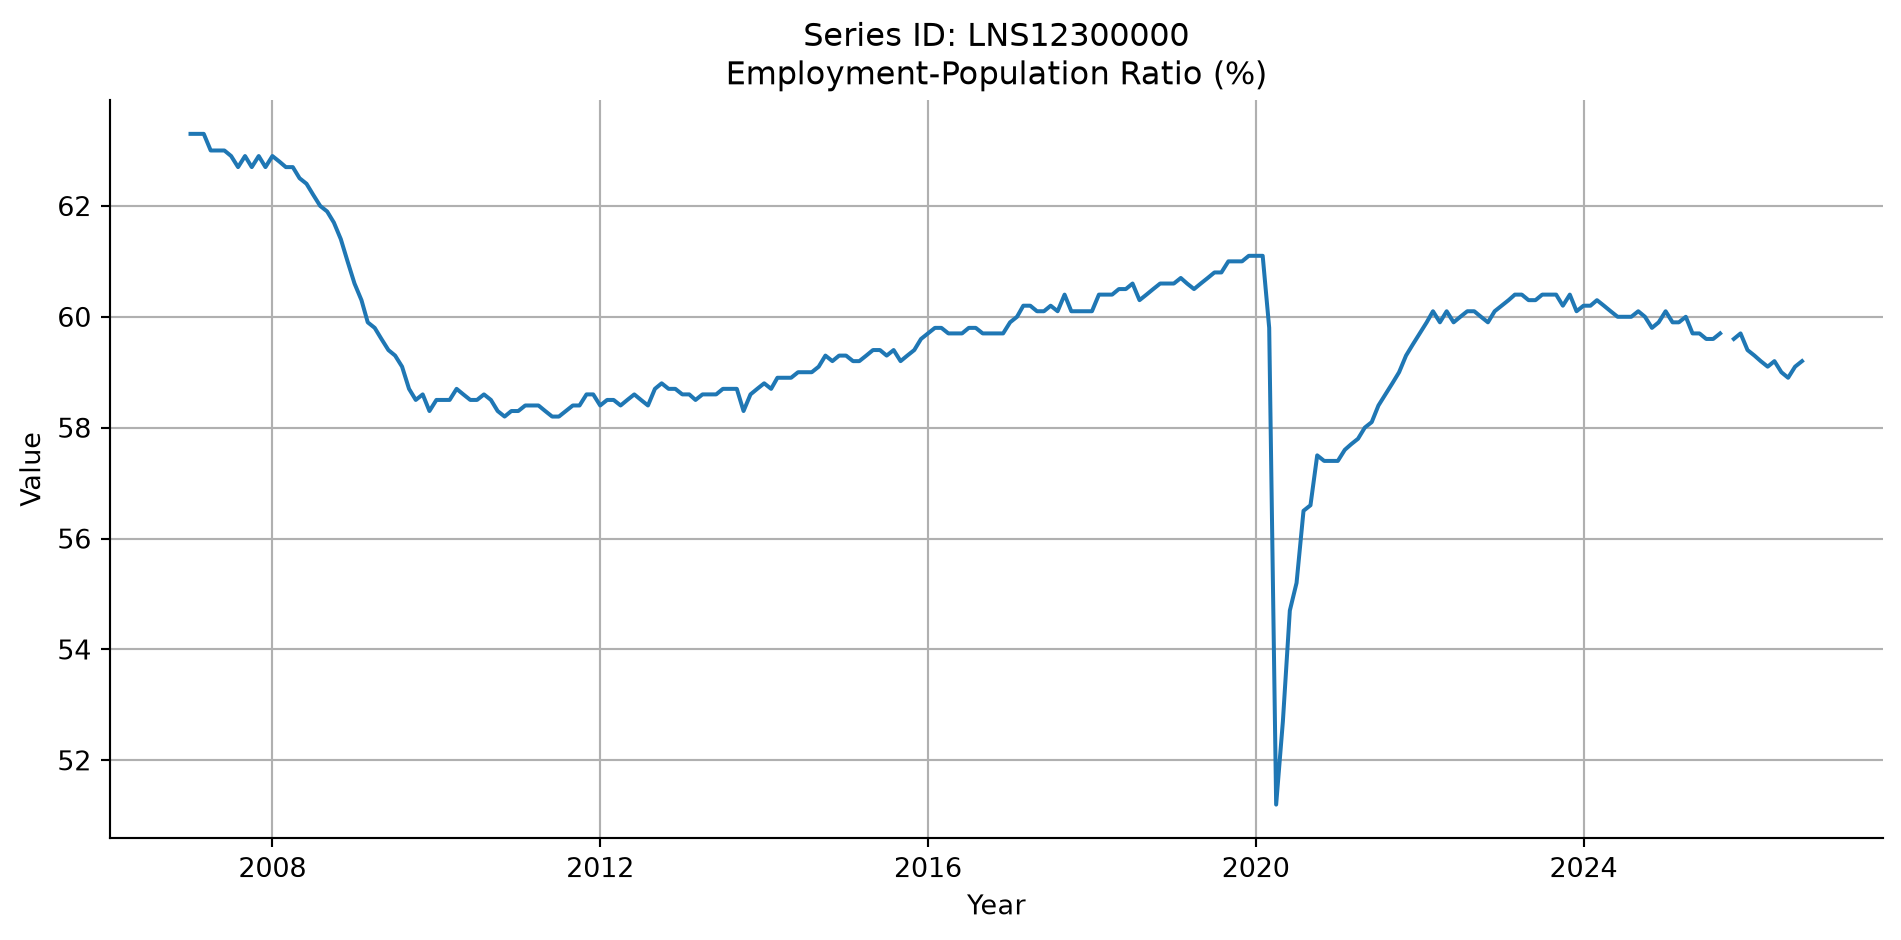

Last 5 recent months of data
shape: (5, 5)
┌─────────────┬────────────┬──────┬────────┬───────┐
│ series_id   ┆ year_month ┆ year ┆ period ┆ value │
│ ---         ┆ ---        ┆ ---  ┆ ---    ┆ ---   │
│ str         ┆ date       ┆ str  ┆ str    ┆ f64   │
╞═════════════╪════════════╪══════╪════════╪═══════╡
│ LNS12300000 ┆ 2026-05-01 ┆ 2026 ┆ M05    ┆ 59.2  │
│ LNS12300000 ┆ 2026-06-01 ┆ 2026 ┆ M06    ┆ 59.0  │
│ LNS12300000 ┆ 2026-07-01 ┆ 2026 ┆ M07    ┆ 58.9  │
│ LNS12300000 ┆ 2026-08-01 ┆ 2026 ┆ M08    ┆ 59.1  │
│ LNS12300000 ┆ 2026-09-01 ┆ 2026 ┆ M09    ┆ 59.2  │
└─────────────┴────────────┴──────┴────────┴───────┘


In [10]:
with BLSClient() as client:
    df = client.fetch_df(series_id="LNS12300000", start_year=2007, end_year=2026)
    client.plot_bls_series(df, "Employment-Population Ratio (%)")
    print("Last 5 recent months of data")
    print(df.tail())

When taking into account population level, we are at a downward trend.  Pre-COVID, the trend was upwards.